In [1]:
# import cython
import numpy as np
import matplotlib.pyplot as plt 
import glob
from ISRpy import beampack
jro0 = beampack.jrobeam

from skimage.morphology import skeletonize

In [2]:
from OXmodeCython import OXmode_cython

In [3]:
npyfilename = 'JM91J_2016014141141.npy'
result_npy = np.load(npyfilename, allow_pickle=True, fix_imports=True)[()]

ionogram = result_npy['mask']
freqs = result_npy['vipir_freqs']
hts = result_npy['vipir_hts']

# plt.imshow(ionogram, origin='lower')

In [4]:
def dist_loss(input, model, radius = 20): # radius is the maxmum loss between two points. 
    loss = 0.0
    input1 = input/np.array([11,700]) * 100 # rescale both model and input to a 100 x 100 dimension
    model1 = model/np.array([11,700]) * 100 #
    fmin, fmax = np.min(model1[:,0]), np.max(model1[:,0])
    hmin, hmax = np.min(model1[:,1]), np.max(model1[:,1])
    for point in input1:
        if point[0] > 100 or point[1] > 100: # point is out of the bound
        # if point[0] < fmin or point[0] > fmax or point[1] < hmin or point[1] > hmax:
            continue
        error = np.min(np.sum((model1-point)**2, axis = 1))
        error = np.clip(error**0.5,max= radius)
        loss += error
#     print(model1)
    return loss

def fps_parabolic(a,z,beta=7):
    def softplus(x):
        return 1/beta*np.log(1+np.exp(x*beta))
    para1 = a[0]-((z-a[1])/a[2]/3)**2
    para2 = a[3]-((z-a[4])/a[5]/3)**2
    para3 = a[6]-((z-a[7])/a[8]/3)**2

    fps1 = (80.6*(softplus(para1) + softplus(para2) + softplus(para3)))**0.5
    # fps2 = (80.6*np.max(np.vstack([para1,para2,para3]), axis=0))**0.5
    return fps1#,fps2

def fps_spline(a,Z):
    a = np.cumsum(a)
    # spline = inter.PchipInterpolator(z,a)
    spline = inter.CubicSpline(z,a)
    fps = spline(Z)
    fps[fps < 0] = 0
    return fps

def evalutate(x_vals, targetO, targetX, fps_func):
    fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps_func(x_vals), fes, dz)
    o = np.vstack((fvsO,vhsO)).T
    x = np.vstack((fvsX,vhsX)).T
    loss  = dist_loss(targetO, o)
    loss += dist_loss(targetX, x)
    return loss

def differential(loss_fun, x_vals, dx : list = [0.05,0.1,0.2]):
    grad = 0
    df = np.zeros_like(x_vals)
    ei = np.zeros_like(x_vals)
    for ddx in dx:
        df *= 0
        ei *= 0
        for i in range(x_vals.shape[0]):
            ei[i] = ddx
            fp = loss_fun(x_vals+ei)
            fn = loss_fun(x_vals-ei)
            ei *= 0
            df[i] = (fp - fn) / (2 * ddx)
        grad += df / np.linalg.norm(df)
    return grad/len(dx), loss_fun(x_vals)

def regularization_loss(x_vals):
    anchors = np.cumsum(x_vals)
    return np.sum(np.abs(anchors)**2)

(0.0, 800.0)

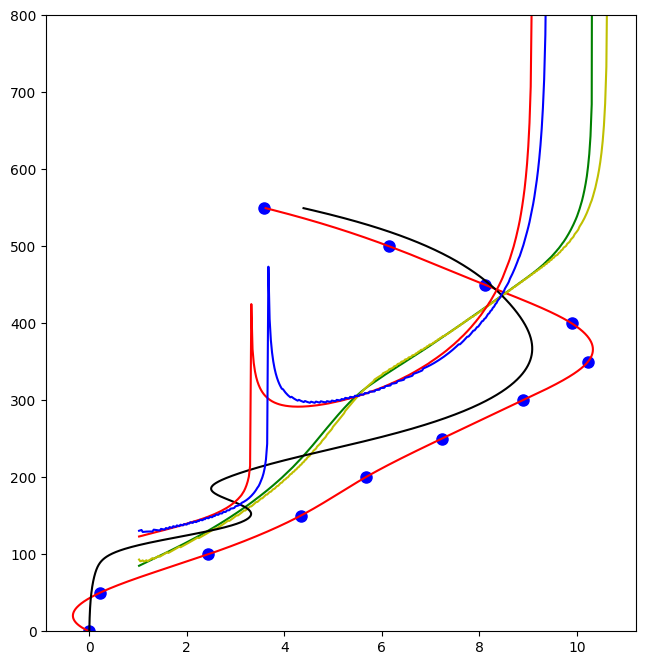

In [16]:
from matplotlib import rcParams
import scipy.interpolate as inter
import datetime
import scipy.constants as const

import time

dt0 = datetime.datetime(2015,4,15)
igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (
        datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()

dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed

#get a list of points to fit a spline
N = 12
zmin = 0
zmax = 550
z = np.linspace(zmin,zmax,N)

#spline fit
# xvals_gold=[0.,0.,2.2,4.,5.5555,6.666,7.7777,
#        8.88888, 9.99922,10.88888889,9.999,8.15]
xvals_gold=[0.,0.22222222,2.4444444,4.33333333,5.6666666,7.22222222,8.88888889,
       10.2222222,9.88888889,8.11111111,6.15,3.5875,]
# spline = inter.PchipInterpolator(z,xvals_gold)
spline = inter.CubicSpline(z,xvals_gold)

#figure.subplot.right
rcParams['figure.subplot.right'] = 0.78
#set up a plot
fig,axes = plt.subplots(1,1,figsize=(9.0,8.0),sharex=True)
ax1 = axes

# height grid
Z = np.arange(0.01,zmax,dz)

fes = []
for iZ in Z:
    r,geoc_lat,lon,aspect,B = jro0.aspect_angle(igrf_year,jro0.xyz0 + jro0.zenith0 * iZ)
    fes += [const.e * np.linalg.norm(B) * 1e-9 / const.m_e /1e6 /2/np.pi] #MHz
fes = np.array(fes)

fps_gold=spline(Z)
# ax1.pcolormesh(freqs,hts,log10(ionograms[3,:,:]),shading='auto')
l, = ax1.plot (xvals_gold,z,color='b',linestyle='none',marker='o',markersize=8)
m, = ax1.plot (spline(Z), Z, 'r-', label='spline fp')

fvsO0,vhsO0,fvsX0,vhsX0=OXmode_cython(fps_gold, fes, dz)
mO, = ax1.plot(fvsO0, vhsO0, 'g-', label='O-trace hv')
mX, = ax1.plot(fvsX0, vhsX0, 'y-', label='X-trace hv')

# xvals = np.array(xvals_gold) + 0.5

xvals = np.array([0.9,400,60,0.2,300,70,0.04,150,20])

fps = fps_parabolic(xvals,Z)
m, = ax1.plot (fps, Z, 'k-', label='spline fp')
fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps, fes, dz)
mO, = ax1.plot(fvsO, vhsO, 'r-', label='O-trace hv')
mX, = ax1.plot(fvsX, vhsX, 'b-', label='X-trace hv')

plt.ylim(0,800) 


In [ ]:
# resize_back = transforms.Resize(ionogram.shape)
# resize_tr = transforms.Resize((572, 572))

def grad_descent_on_seg(filename):
# for filename in filenames:
    # processed_files = glob.glob1('testset_fitting_transformer/','*.npy')
    # if filename in processed_files:
    #     return
    data = np.load('seg_result_transformer/'+filename,allow_pickle=True)[()]
    img = data['image']
    imgO = skeletonize(data['imgO'])
    imgX = skeletonize(data['imgX'])

    Y, X = imgO.nonzero()
    fvsO0 = freqs[X]
    vhsO0 = hts[Y]
    targetO = np.vstack((fvsO0,vhsO0)).T

    Y, X = imgX.nonzero()
    fvsX0 = freqs[X]
    vhsX0 = hts[Y]
    targetX = np.vstack((fvsX0,vhsX0)).T

    fof2 = fvsO0.max()
    x_vals = np.array([0.0, 0., 1., 1.8888889300000002, 1.3333332699999998, 1.5555556199999998, 1.6666666700000006, 1.3333333099999987, -0.33333330999999866, -1.777777780000001, -1.9611111099999992, -2.5625000000000004])
    # x_vals = np.array([0., 0.,  2.2 ,1.8, 1.5555, 1.1105, 1.1117, 1.11118, 1.11034, 0.88966889, -0.88988889, -1.849])
    x_vals = x_vals / x_vals.cumsum().max() * fof2

    losses = []
    all_xvals = []
    lr = 4e-2
    grad_limit = 1e3
    gr_mem = 0.1
    wd = 1e-4
    # x_vals=np.array([0.,0.22222222,2.4444444,4.33333333,5.6666666,7.22222222,8.88888889, 10.2222222,9.88888889,8.11111111,6.15,3.5875,0.,0.,0.,0.,0.])

    grad = 0
    for it in range(1):
        grad_cur, loss = differential(lambda xv: regularization_loss(xv) + evalutate(xv,  targetO, targetX, lambda x: fps_spline(x, Z)) , x_vals=x_vals) # 
        grad_cur = np.clip(grad_cur, min=-grad_limit, max = grad_limit)
        grad = grad_cur #grad * gr_mem + grad_cur * (1-grad_cur)
        
        x_vals += -1 * lr * grad #- wd*x_vals
        if it % 40 == 0: lr *= 0.71
        losses += [loss]
        all_xvals += [x_vals]

    np.save(f'testset_fitting_transformer/{filename}', {'filename':filename, 'image':img, 'imgO': imgO, 'imgX': imgX, 'all_xvals': all_xvals, 'all_losses':losses})
    
    fig,axes = plt.subplots(1,3,figsize=(15,5),sharex=False)
    ax1 = axes[0]
    ax1.set_ylim(0,700)
    temp = np.copy(imgO)
    temp[imgX > 0] = 2
    ax1.pcolormesh(freqs,hts,temp,shading='auto')
    fps = fps_spline(x_vals, Z)
    m, = ax1.plot (fps, Z, 'k-', label='spline fp')
    fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps, fes, dz)
    mO, = ax1.plot(fvsO, vhsO, 'r-', label='O-trace hv')
    mX, = ax1.plot(fvsX, vhsX, 'b-', label='X-trace hv')
    ax1.set_ylim(0,700)
    # ax1.set_xlim(0, 12.5)
    ax2 = axes[1]
    ax2.set_ylim(0,700)
    # ax2.set_xlim(0, 12.5)
    ax2.pcolormesh(freqs,hts,img,shading='auto')
    ax3 = axes[2]
    # ax3.set_xlim(0, 100)
    ax3.plot(losses)
    fig.savefig(f'anchor_test/{filename[0:-4]}.png', bbox_inches='tight', dpi=300)
    plt.close()
    return
    

In [20]:
from joblib import Parallel, delayed
# from multiprocessing import Pool

filenames = glob.glob1('seg_result_transformer/','*.npy')
filenames.sort()

Parallel(n_jobs=16)(delayed(grad_descent_on_seg)(f) for f in filenames[:16])
# grad_descent_on_seg(filenames[0])
# processes_pool = Pool(5)
# processes_pool.map(grad_descent_on_seg, filenames)
# processes_pool.close()

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [ ]:
x_vals=np.array([0.,0.22222222,2.4444444,4.33333333,5.6666666,7.22222222,8.88888889, 10.2222222,9.88888889,8.11111111,6.15,3.5875,0.,0.,0.,0.,0.])
temp = x_vals[1:] - x_vals[:-1]
print([float(x_vals[0])]+temp.tolist())
